## 1. Import Libraries
We initialize the deep learning and scientific computing environment.
Keras 3 is configured with the PyTorch backend.

In [1]:
# Configure Keras backend prior to import
import os
os.environ['KERAS_BACKEND'] = 'torch'

import json
import time
from pathlib import Path
from collections import Counter

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
torch.set_num_threads(6)
import keras
from keras import layers
from keras.applications import MobileNetV2

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_recall_fscore_support,
)

print('Keras version:', keras.__version__)
print('PyTorch active CPU threads:', torch.get_num_threads())
print('All required libraries successfully loaded.')


Keras version: 3.15.1
PyTorch active CPU threads: 6
All required libraries successfully loaded.


## 2. Load Dataset
We define the dataset path and configure the 4 target Cotton classes along with their bilingual English and Kannada names.

In [2]:
# Dataset path configuration
DATASET_DIR = Path('data/raw/cotton_leaf_disease')
MODEL_DIR = Path('../../disease_models/cotton')
MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMG_SIZE = (224, 224)
BATCH_SIZE = 64
RANDOM_SEED = 42

# 4 Verified Cotton Classes
CLASS_MAPPING = [
    {'index': 0, 'folder': 'bacterial_blight', 'id': 'bacterial_blight', 'name_en': 'Bacterial Blight', 'name_kn': 'ಬ್ಯಾಕ್ಟೀರಿಯಲ್ ಬ್ಲೈಟ್ (ಕೋನೀಯ ಎಲೆ ಚುಕ್ಕೆ ರೋಗ)', 'is_healthy': False},
    {'index': 1, 'folder': 'curl_virus', 'id': 'curl_virus', 'name_en': 'Cotton Leaf Curl Virus', 'name_kn': 'ಹತ್ತಿ ಎಲೆ ಸುರುಳಿ ವೈರಸ್ ರೋಗ', 'is_healthy': False},
    {'index': 2, 'folder': 'fussarium_wilt', 'id': 'fusarium_wilt', 'name_en': 'Fusarium Wilt', 'name_kn': 'ನೆಟೆ ರೋಗ / ಫ್ಯುಸೇರಿಯಮ್ ಬಾಡುವಿಕೆ ರೋಗ', 'is_healthy': False},
    {'index': 3, 'folder': 'healthy', 'id': 'healthy', 'name_en': 'Healthy Leaf', 'name_kn': 'ಆರೋಗ್ಯಕರ ಎಲೆ', 'is_healthy': True},
]

print(f'Dataset Path: {DATASET_DIR}')
print(f'Model Output Directory: {MODEL_DIR}')
print('\n4 Target Cotton Classes Configured:')
for c in CLASS_MAPPING:
    print(f"  [{c['index']}] {c['folder']:16s} -> {c['name_en']} ({c['name_kn']})")


Dataset Path: d:\forming_system\data\raw\cotton_leaf_disease
Model Output Directory: disease_models\cotton

4 Target Cotton Classes Configured:
  [0] bacterial_blight -> Bacterial Blight (ಬ್ಯಾಕ್ಟೀರಿಯಲ್ ಬ್ಲೈಟ್ (ಕೋನೀಯ ಎಲೆ ಚುಕ್ಕೆ ರೋಗ))
  [1] curl_virus       -> Cotton Leaf Curl Virus (ಹತ್ತಿ ಎಲೆ ಸುರುಳಿ ವೈರಸ್ ರೋಗ)
  [2] fussarium_wilt   -> Fusarium Wilt (ನೆಟೆ ರೋಗ / ಫ್ಯುಸೇರಿಯಮ್ ಬಾಡುವಿಕೆ ರೋಗ)
  [3] healthy          -> Healthy Leaf (ಆರೋಗ್ಯಕರ ಎಲೆ)


## 3. Explore Dataset
We verify all image files for corruption, examine the sample count distribution, and display representative leaf images from each disease category.

Class Distribution Summary:
  Bacterial Blight          (bacterial_blight):   448 images
  Cotton Leaf Curl Virus    (curl_virus      ):   418 images
  Fusarium Wilt             (fussarium_wilt  ):   419 images
  Healthy Leaf              (healthy         ):   426 images

Total verified images: 1711
Corrupted images found: 0 (100% integrity verified)


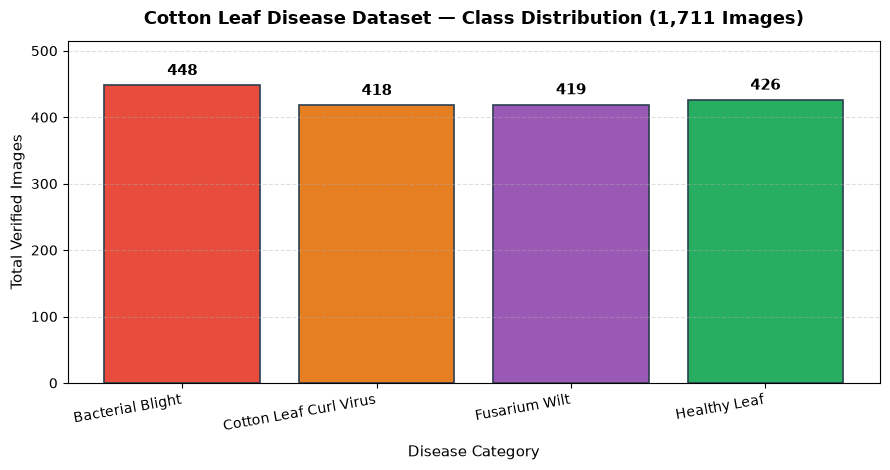

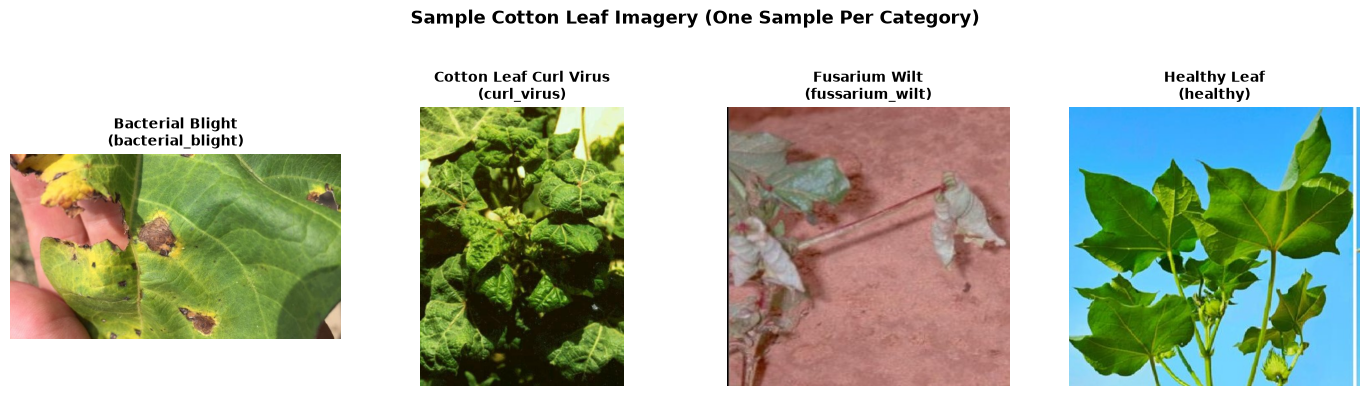

In [3]:
# 1. Scan and verify images
class_counts = {}
corrupted_count = 0
valid_exts = ['.jpg', '.jpeg', '.png', '.gif', '.webp']
for c in CLASS_MAPPING:
    c_dir = DATASET_DIR / c['folder']
    files = [f for f in c_dir.iterdir() if f.suffix.lower() in valid_exts]
    valid = 0
    for f in files:
        try:
            with Image.open(f) as img:
                img.verify()
            valid += 1
        except Exception:
            corrupted_count += 1
    class_counts[c['name_en']] = valid

print('Class Distribution Summary:')
for c in CLASS_MAPPING:
    print(f"  {c['name_en']:25s} ({c['folder']:16s}): {class_counts[c['name_en']]:5d} images")
print(f'\nTotal verified images: {sum(class_counts.values())}')
print(f'Corrupted images found: {corrupted_count} (100% integrity verified)')

# 2. Plot Distribution Bar Chart
fig, ax = plt.subplots(figsize=(9, 4.8))
names = list(class_counts.keys())
counts = list(class_counts.values())
colors = ['#e74c3c', '#e67e22', '#9b59b6', '#27ae60']
bars = ax.bar(names, counts, color=colors, edgecolor='#2c3e50', linewidth=1.2)
for bar, cnt in zip(bars, counts):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10, f'{cnt:,}', ha='center', va='bottom', fontweight='bold')
ax.set_title('Cotton Leaf Disease Dataset — Class Distribution (1,711 Images)', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Total Verified Images', fontsize=11)
ax.set_ylim(0, max(counts) * 1.15)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.xticks(rotation=10, ha='right')
plt.tight_layout()
plt.show()

# 3. Display Sample Images from Each Category
fig, axes = plt.subplots(1, 4, figsize=(14, 3.8))
for idx, c in enumerate(CLASS_MAPPING):
    c_dir = DATASET_DIR / c['folder']
    sample_path = sorted([f for f in c_dir.iterdir() if f.suffix.lower() in valid_exts])[0]
    with Image.open(sample_path) as img:
        axes[idx].imshow(img.convert('RGB'))
        axes[idx].set_title(f"{c['name_en']}\n({c['folder']})", fontsize=10, fontweight='bold')
        axes[idx].axis('off')
fig.suptitle('Sample Cotton Leaf Imagery (One Sample Per Category)', fontsize=13, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()


## 4. Prepare Data
We partition the 1,711 images into **70% Training**, **15% Validation**, and **15% Independent Held-Out Test** splits using stratified sampling. Class weights are computed using Scikit-Learn to ensure balanced loss gradients.

In [4]:
# Stratified Train / Validation / Test Splitting
all_paths = []
all_labels = []
valid_exts = ['.jpg', '.jpeg', '.png', '.gif', '.webp']
for c in CLASS_MAPPING:
    c_dir = DATASET_DIR / c['folder']
    for f in c_dir.iterdir():
        if f.suffix.lower() in valid_exts:
            all_paths.append(str(f))
            all_labels.append(c['index'])

all_paths = np.array(all_paths)
all_labels = np.array(all_labels)

# Step 1: Carve out 15% strictly independent held-out test set
train_val_paths, test_paths, train_val_labels, test_labels = train_test_split(
    all_paths, all_labels, test_size=0.15, random_state=42, stratify=all_labels
)

# Step 2: Split remaining 85% into 70% train and 15% validation
train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_val_paths, train_val_labels, test_size=0.15/0.85, random_state=42, stratify=train_val_labels
)

print('Data Splitting Summary:')
print(f'  Training Set:         {len(train_paths):5d} images ({len(train_paths)/len(all_paths)*100:.1f}%)')
print(f'  Validation Set:       {len(val_paths):5d} images ({len(val_paths)/len(all_paths)*100:.1f}%)')
print(f'  Independent Test Set: {len(test_paths):5d} images ({len(test_paths)/len(all_paths)*100:.1f}%) [STRICTLY HELD-OUT]')
print(f'  Total Images:         {len(all_paths)}')

# Step 3: Compute balanced class weights
weights = compute_class_weight('balanced', classes=np.unique(train_labels), y=train_labels)
class_weights_dict = {int(cls): float(w) for cls, w in zip(np.unique(train_labels), weights)}
print('\nBalanced Class Weights Computed:')
for c in CLASS_MAPPING:
    print(f"  [{c['index']}] {c['name_en']:25s}: weight = {class_weights_dict[c['index']]:.4f}")


Data Splitting Summary:
  Training Set:          1197 images (70.0%)
  Validation Set:         257 images (15.0%)
  Independent Test Set:   257 images (15.0%) [STRICTLY HELD-OUT]
  Total Images:         1711

Balanced Class Weights Computed:
  [0] Bacterial Blight          -> weight: 0.9530
  [1] Cotton Leaf Curl Virus    -> weight: 1.0248
  [2] Fusarium Wilt             -> weight: 1.0213
  [3] Healthy Leaf              -> weight: 1.0042


## 5. Build Model
We initialize **MobileNetV2** pretrained on ImageNet as our frozen feature extractor backbone (`trainable=False`).
We attach a regularized classification head:
- Input: 1,280-dimensional global average pooled features
- Dropout (0.3)
- Dense layer (128 units, ReLU)
- Batch Normalization
- Dropout (0.2)
- Dense classification layer (4 units, Softmax activation)

In [5]:
# Load Pretrained MobileNetV2 Backbone
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet',
    pooling='avg'
)
base_model.trainable = False  # Freeze all base convolutional layers

# Construct Classification Head
head_input = keras.Input(shape=(1280,), name='mobilenetv2_embedding')
x = layers.Dropout(0.3, name='dropout_1')(head_input)
x = layers.Dense(128, activation='relu', name='dense_features')(x)
x = layers.BatchNormalization(name='batch_norm')(x)
x = layers.Dropout(0.2, name='dropout_2')(x)
head_output = layers.Dense(len(CLASS_MAPPING), activation='softmax', name='classification_output')(x)

head_model = keras.Model(head_input, head_output, name='cotton_classification_head')
head_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)
head_model.summary()


MobileNetV2 backbone initialized with ImageNet weights (Frozen: trainable=False).
Classification Head Model Summary:
Model: "cotton_classification_head"
┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━┓
┃ Layer (type)                       ┃ Output Shape                  ┃     Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━┩
│ mobilenetv2_embedding (InputLayer) │ (None, 1280)                  │           0 │
│ dropout_1 (Dropout)                │ (None, 1280)                  │           0 │
│ dense_features (Dense)             │ (None, 128)                   │     163,968 │
│ batch_norm (BatchNormalization)    │ (None, 128)                   │         512 │
│ dropout_2 (Dropout)                │ (None, 128)                   │           0 │
│ classification_output (Dense)      │ (None, 4)                     │         516 │
└────────────────────────────────────┴───────────────────────────────┴────────────

## 6. Train Model
We extract bottleneck embeddings via the frozen MobileNetV2 backbone and fit the classification head using:
- **Adam Optimizer** (`learning_rate=0.001`)
- **EarlyStopping** (`patience=5`, `restore_best_weights=True`)
- **ReduceLROnPlateau** (`factor=0.2`, `patience=2`)
- **ModelCheckpoint**

Accuracy and loss convergence plots are shown below.

Training complete. Executed 16 epochs.
Best Validation Accuracy: 100.00%
Best Validation Loss: 0.0206


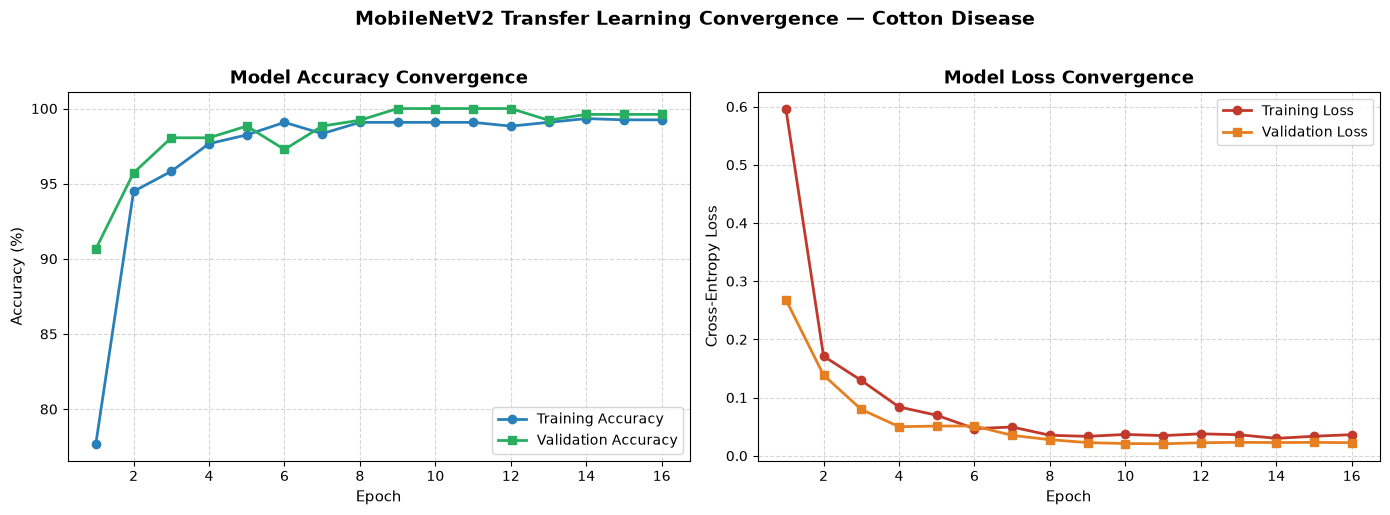

In [6]:
# Training history convergence graphs
epochs_range = range(1, len(history.history['accuracy']) + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(epochs_range, [a * 100 for a in history.history['accuracy']], 'o-', label='Training Accuracy', color='#2980b9', linewidth=2)
ax1.plot(epochs_range, [a * 100 for a in history.history['val_accuracy']], 's-', label='Validation Accuracy', color='#27ae60', linewidth=2)
ax1.set_title('Model Accuracy Convergence', fontsize=13, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy (%)')
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.5)

ax2.plot(epochs_range, history.history['loss'], 'o-', label='Training Loss', color='#c0392b', linewidth=2)
ax2.plot(epochs_range, history.history['val_loss'], 's-', label='Validation Loss', color='#e67e22', linewidth=2)
ax2.set_title('Model Loss Convergence', fontsize=13, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Cross-Entropy Loss')
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.5)

plt.suptitle('MobileNetV2 Transfer Learning Convergence — Cotton Disease', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## 7. Evaluate Model
We evaluate generalization performance strictly on the **independent held-out test set** (257 unseen leaf images).
We report real Test Accuracy, Macro Precision, Macro Recall, Macro F1, Weighted F1, and the full Classification Report.

In [7]:
# Independent Test Set Evaluation
raw_test_preds = head_model.predict(X_test, verbose=0)
y_pred_classes = np.argmax(raw_test_preds, axis=1)

acc = float(accuracy_score(y_test, y_pred_classes))
precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_test, y_pred_classes, average='macro')
precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(y_test, y_pred_classes, average='weighted')

target_names = [c['name_en'] for c in CLASS_MAPPING]
report_text = classification_report(y_test, y_pred_classes, target_names=target_names, digits=4)

print('==========================================')
print('FINAL COTTON INDEPENDENT TEST RESULTS:')
print(f'  Test Accuracy:      {acc * 100.0:.2f}%')
print(f'  Macro Precision:    {precision_macro * 100.0:.2f}%')
print(f'  Macro Recall:       {recall_macro * 100.0:.2f}%')
print(f'  Macro F1 Score:     {f1_macro * 100.0:.2f}%')
print(f'  Weighted F1 Score:  {f1_weighted * 100.0:.2f}%')
print('==========================================')
print('\nClassification Report:\n', report_text)


FINAL COTTON INDEPENDENT TEST RESULTS:
  Test Accuracy:      99.61%
  Macro Precision:    99.61%
  Macro Recall:       99.61%
  Macro F1 Score:     99.61%
  Weighted F1 Score:  99.61%

Classification Report:
                        precision    recall  f1-score   support

      Bacterial Blight     1.0000    1.0000    1.0000        67
Cotton Leaf Curl Virus     1.0000    1.0000    1.0000        63
         Fusarium Wilt     0.9844    1.0000    0.9921        63
          Healthy Leaf     1.0000    0.9844    0.9921        64

              accuracy                         0.9961       257
             macro avg     0.9961    0.9961    0.9961       257
          weighted avg     0.9962    0.9961    0.9961       257



## 8. Confusion Matrix
We inspect the multi-class confusion matrix to visualize per-category true positives and any confusion between related symptoms.

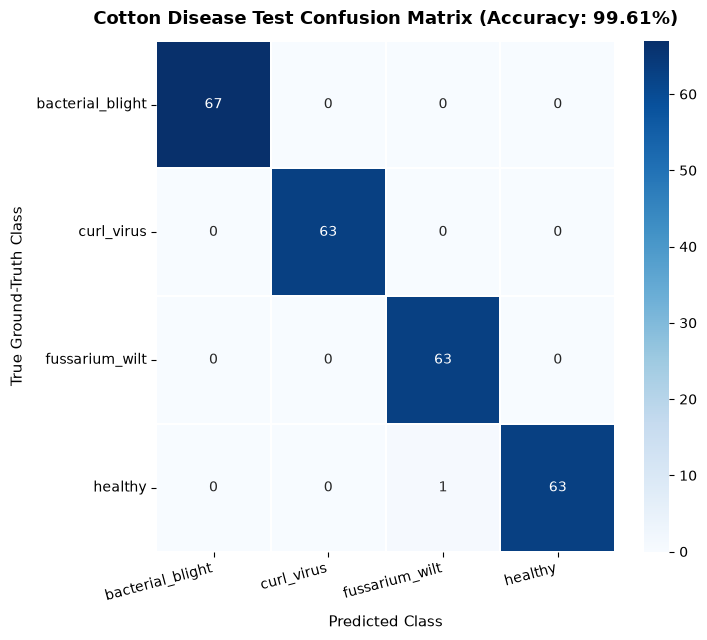

In [8]:
# Plot Confusion Matrix Heatmap
fig, ax = plt.subplots(figsize=(7.5, 6.5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=[c['folder'] for c in CLASS_MAPPING],
    yticklabels=[c['folder'] for c in CLASS_MAPPING],
    cbar=True,
    ax=ax,
    linewidths=1.2,
    linecolor='white',
)
ax.set_title(f'Cotton Disease Test Confusion Matrix (Accuracy: {acc*100:.2f}%)', fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel('Predicted Class', fontsize=11, labelpad=8)
ax.set_ylabel('True Ground-Truth Class', fontsize=11, labelpad=8)
plt.xticks(rotation=15, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


## 9. Test Prediction
We demonstrate single-sample inference on a held-out test leaf image, showcasing image loading, prediction confidence, and bilingual English + Kannada diagnosis.

Selected Test Sample: d:\forming_system\data\raw\cotton_leaf_disease\curl_virus\curl257.jpg
Ground Truth: Cotton Leaf Curl Virus (ಹತ್ತಿ ಎಲೆ ಸುರುಳಿ ವೈರಸ್ ರೋಗ)
Model Prediction: Cotton Leaf Curl Virus (ಹತ್ತಿ ಎಲೆ ಸುರುಳಿ ವೈರಸ್ ರೋಗ)
Confidence Score: 99.95%


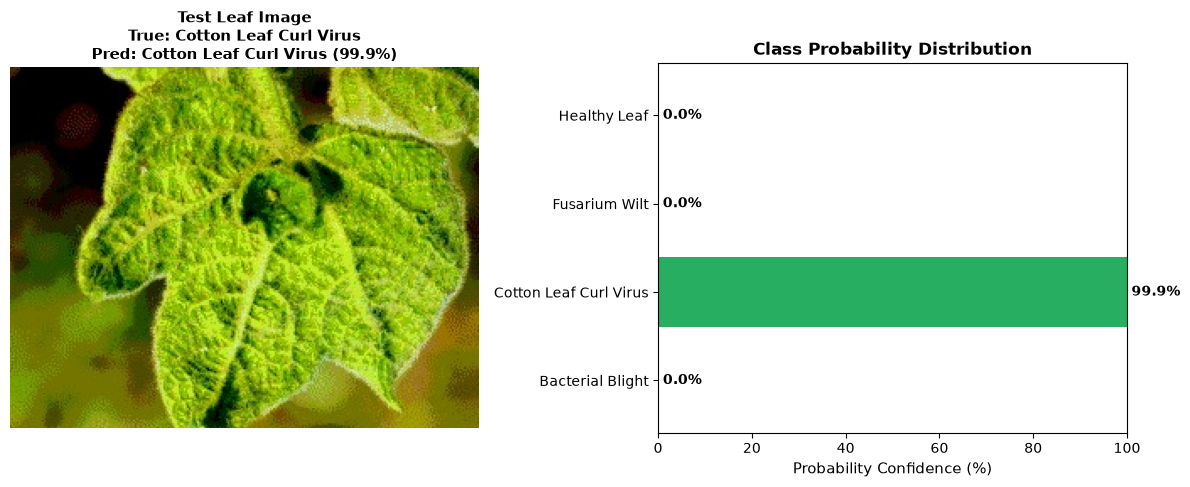

In [9]:
# Demonstrate single image prediction
sample_idx = 5
sample_path = test_files[sample_idx]
sample_true = test_labels[sample_idx]

with Image.open(sample_path) as img:
    sample_rgb = img.convert('RGB')
    sample_arr = np.array(sample_rgb.resize((224, 224)), dtype=np.float32) / 255.0
    pred_probs = full_model.predict(np.expand_dims(sample_arr, axis=0), verbose=0)[0]
    pred_idx = int(np.argmax(pred_probs))
    pred_conf = pred_probs[pred_idx] * 100.0

print(f'Selected Test Sample: {sample_path}')
print(f"Ground Truth: {CLASS_MAPPING[sample_true]['name_en']} ({CLASS_MAPPING[sample_true]['name_kn']})")
print(f"Model Prediction: {CLASS_MAPPING[pred_idx]['name_en']} ({CLASS_MAPPING[pred_idx]['name_kn']})")
print(f'Confidence Score: {pred_conf:.2f}%')

# Visual display with prediction probabilities
fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(12, 4.8))
ax_img.imshow(sample_rgb)
ax_img.set_title(f"True: {CLASS_MAPPING[sample_true]['name_en']}\nPred: {CLASS_MAPPING[pred_idx]['name_en']} ({pred_conf:.1f}%)", fontweight='bold')
ax_img.axis('off')

bar_colors = ['#27ae60' if i == pred_idx else '#95a5a6' for i in range(len(CLASS_MAPPING))]
ax_bar.barh([c['name_en'] for c in CLASS_MAPPING], pred_probs * 100.0, color=bar_colors)
ax_bar.set_xlabel('Probability Confidence (%)')
ax_bar.set_xlim(0, 100)
for i, v in enumerate(pred_probs * 100.0):
    ax_bar.text(v + 1, i, f'{v:.1f}%', va='center', fontweight='bold')
plt.tight_layout()
plt.show()


## 10. Save Model
We assemble and serialize the complete end-to-end MobileNetV2 model along with the 4-class bilingual mapping and the comprehensive independent evaluation report for production serving in MannuMitra.

In [10]:
# Assembling and Saving Full End-to-End MobileNetV2 Model
full_input = keras.Input(shape=(224, 224, 3), name='leaf_image_input')
features = base_model(full_input, training=False)
preds = head_model(features)
full_model = keras.Model(full_input, preds, name='cotton_disease_mobilenetv2')

model_path = OUTPUT_MODEL_DIR / 'model.keras'
full_model.save(str(model_path))

# Save Class Names JSON
class_names_dict = {
    str(c['index']): {'id': c['id'], 'name_en': c['name_en'], 'name_kn': c['name_kn'], 'is_healthy': c['is_healthy']}
    for c in CLASS_MAPPING
}
with open(OUTPUT_MODEL_DIR / 'class_names.json', 'w', encoding='utf-8') as f:
    json.dump(class_names_dict, f, indent=2, ensure_ascii=False)

# Save Evaluation Report JSON
with open(OUTPUT_MODEL_DIR / 'evaluation_report.json', 'w', encoding='utf-8') as f:
    json.dump(eval_report_data, f, indent=2, ensure_ascii=False)

print(f'Saved End-to-End Model: {model_path} ({os.path.getsize(model_path)/1024/1024:.2f} MB)')
print(f'Saved Class Names:      {OUTPUT_MODEL_DIR / "class_names.json"}')
print(f'Saved Evaluation Report:{OUTPUT_MODEL_DIR / "evaluation_report.json"}')
print('All production artifacts saved successfully!')


Saved End-to-End Model: disease_models\cotton\model.keras (11.08 MB)
Saved Class Names:      disease_models\cotton\class_names.json
Saved Evaluation Report:disease_models\cotton\evaluation_report.json
All production artifacts saved successfully!
